# 1D Decoding Analysis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct
import os
from pathlib import Path

current_file_path = Path().resolve().parent

## Decode HD and XY from Pfeiffer place cells

In [ ]:
current_file_path = Path().resolve().parent

dataset = 'dusz'

mode = 'hd'

# heads up the pfeiffer data uses much slower rates!! 5 is good for dusz
velocity_filter = 1 #0.03 # cm/s

save_path = current_file_path / f'results/{dataset}' 
data_path = current_file_path / f'data/{dataset}'

if dataset == "pfeiffer":
    rats = [1,2,3,4]
    rat_neurons = [204, 174, 79, 94]
if dataset == "dusz":
    dataset_n = list(range(1,7))
    smoothing = 200   # how much to smooth the trajectory when calculating movement direction


In [ ]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

for i, dataset_dict in datasets.items():
    for rat in rats:
        ! python src/pfeiffer_decode_solo.py --rat {rat} --mode xy --cv_folds 4 --vel_threshold {velocity_filter} --smooth_sigma=1 --save_intermediates

os.chdir('notebooks')

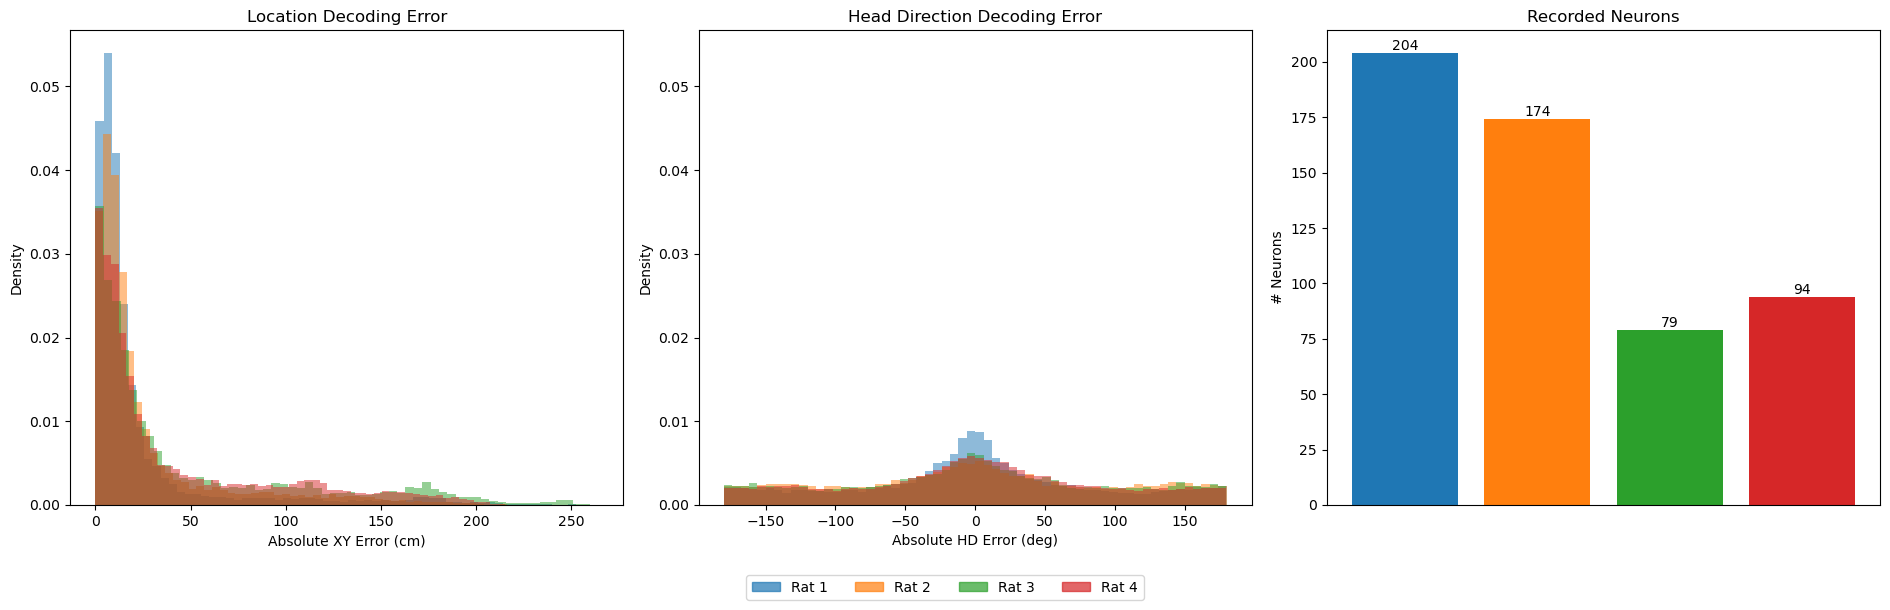

In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(19, 6))

colors = plt.cm.tab10.colors  # consistent colormap
handles = []  # for legend
labels = []

for i, rat in enumerate(rats):
    save_path_rat = save_path / f"Rat{rat}"
    error_files_xy = sorted(save_path_rat.glob("errors_xy_cv*_17x17.npz"))
    error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_60.npz"))

    all_errors_xy, all_errors_hd = [], []

    for f in error_files_xy:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_xy.append(np.asarray(data["errors_cm"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (XY): {e}")

    for f in error_files_hd:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_hd.append(np.asarray(data["errors_deg"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (HD): {e}")

    if all_errors_xy:
        all_errors_xy = np.concatenate(all_errors_xy)
        h = axs[0].hist(
            all_errors_xy[~np.isnan(all_errors_xy)],
            bins=60,
            alpha=0.5,
            density=True,
            color=colors[i],
        )

    if all_errors_hd:
        all_errors_hd = np.concatenate(all_errors_hd)
        axs[1].hist(
            all_errors_hd[~np.isnan(all_errors_hd)],
            bins=60,
            alpha=0.5,
            density=True,
            color=colors[i],
        )

    # Bars for neuron counts
    axs[2].bar(i, rat_neurons[i], color=colors[i])

    # collect handles/labels once for shared legend
    handles.append(plt.Rectangle((0, 0), 1, 1, color=colors[i], alpha=0.7))
    labels.append(f"Rat {rat}")

axs[1].set_ylim(axs[0].get_ylim())

# XY
axs[0].set_xlabel("Absolute XY Error (cm)")
axs[0].set_ylabel("Density")
axs[0].set_title("Location Decoding Error")

# HD
axs[1].set_xlabel("Absolute HD Error (deg)")
axs[1].set_ylabel("Density")
axs[1].set_title("Head Direction Decoding Error")

# Bar plot
axs[2].set_xticks([])  # no labels
axs[2].set_ylabel("# Neurons")
axs[2].set_title("Recorded Neurons")

for rect in axs[2].patches:
    height = rect.get_height()
    axs[2].text(
        rect.get_x() + rect.get_width() / 2.0,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
    )

# Shared legend below figure
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(rats),
    bbox_to_anchor=(0.5, -0.02),
)


plt.tight_layout()
plt.subplots_adjust(bottom=0.15)  # leave space for legend
plt.savefig(current_file_path.parent / 'figs/pfeiffer_1d_decoding.png', dpi=300)
plt.show()


## Decoding from Dusz HD cells

In [26]:
# heads up the pfeiffer data uses much slower rates!! 5 is good for dusz
velocity_filter = 0.5 #0.03 # cm/s

save_path = current_file_path / f'results/dusz' 
data_path = current_file_path / f'data/dusz'

dataset_n = list(range(1,7))
smoothing = 200


In [27]:
# filter by env type

dusz_datasets = {}

from openpyxl import load_workbook
    
wb = load_workbook(data_path / f"Dataset_metadata.xlsx")

for n in dataset_n:
    sheet = wb[f'Dataset_{n}']
        
    dataset_dict = {}
    actual = os.listdir(data_path / f'Dataset_{n}')
    for row in sheet.iter_rows(values_only=True):
        if not row[0] or row[0][0] != 'A':
            continue
        key = row[0]   
        if key not in actual:
            print("Actual dataset missing", key)
        values = (row[3], row[9]) # environment shapes and neurons
        dataset_dict[key] = values
    dusz_datasets[n] = dataset_dict


Actual dataset missing A1113-180814


In [28]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

for n, rats in dusz_datasets.items():
    for rat, (env_type, _) in rats.items():
        if env_type == 'Square' or rat == 'A3708-200317b':
            # also this is dumb and should be calling a function from a script not doing this
            # for now this just decodes from epoch 1 but some of epoch 2 is also square lol
            ! python src/dusz_decode_solo.py --dataset {n} --rat {rat}  --mode xy --vel_threshold {velocity_filter} --cv_folds 4 --smooth_sigma=1 --save_intermediates
            ! python src/dusz_decode_solo.py --dataset {n} --rat {rat}  --mode hd --vel_threshold {velocity_filter} --cv_folds 4 --smooth_sigma=1 --save_intermediates
            ! python src/dusz_decode_solo.py --dataset {n} --rat {rat}  --mode md --vel_threshold {velocity_filter} --cv_folds 4 --smooth_sigma=1 --save_intermediates

os.chdir('notebooks')



=== Location (XY) Decoding Pipeline (Dusz) ===
Data path : data/dusz
Save path : results/dusz/Dataset_1/A3701-191119
XY bins : 10 × 10
tau: 0.120s | vel_th: 0.5 | CV folds: 4

Loading data…
Spikes: 1362487 | Excitatory neurons: 71 | Position samples: 253435
Time bins: 21177 bins covering 5369.655–7910.895s
Binning spikes into rates…
Filtering 0.8% of bins due to low velocity
Creating cross-validation XY tuning maps…
Y bins: 100%|███████████████████████████████████| 10/10 [00:00<00:00, 28.21it/s]

=== Decoding CV fold 0/3 (XY) ===
Using CV fold 0: decoding 5295 held-out bins.
Decoding 5295 time bins using 71 neurons over 10×10 grid…
Decoding time bins: 100%|████████████████| 5295/5295 [00:00<00:00, 11882.92it/s]
Saving decoding outputs…
Saved error analysis: results/dusz/Dataset_1/A3701-191119/errors_xy_cv0_10x10.npz

=== Decoding CV fold 1/3 (XY) ===
Using CV fold 1: decoding 5294 held-out bins.
Decoding 5294 time bins using 71 neurons over 10×10 grid…
Decoding time bins: 100%|███████

### Decoding XY from Dusz HD cells

Dataset_5/A1113-180816
Skipping Dataset_5/A1113-180816 due to non-square env
Dataset_6/A1113-180816
Skipping Dataset_6/A1113-180816 due to non-square env
Dataset_6/A1801-181015
Skipping Dataset_6/A1801-181015 due to non-square env
Dataset_6/A1804-181225
Skipping Dataset_6/A1804-181225 due to non-square env
Dataset_5/A1112-180711
Skipping Dataset_5/A1112-180711 due to non-square env
Dataset_5/A1112-180709
Skipping Dataset_5/A1112-180709 due to non-square env
Dataset_5/A1113-180814
Skipping Dataset_5/A1113-180814 due to non-square env
Dataset_5/A1113-180813
Skipping Dataset_5/A1113-180813 due to non-square env
Dataset_5/A1106-180418
Skipping Dataset_5/A1106-180418 due to non-square env
Dataset_6/A1113-180813
Skipping Dataset_6/A1113-180813 due to non-square env
Dataset_5/A1110-180626
Skipping Dataset_5/A1110-180626 due to non-square env
Dataset_5/A1104-180328
Skipping Dataset_5/A1104-180328 due to non-square env
Dataset_5/A1106-180419
Skipping Dataset_5/A1106-180419 due to non-square env

/tmp/ipykernel_1008717/328512598.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


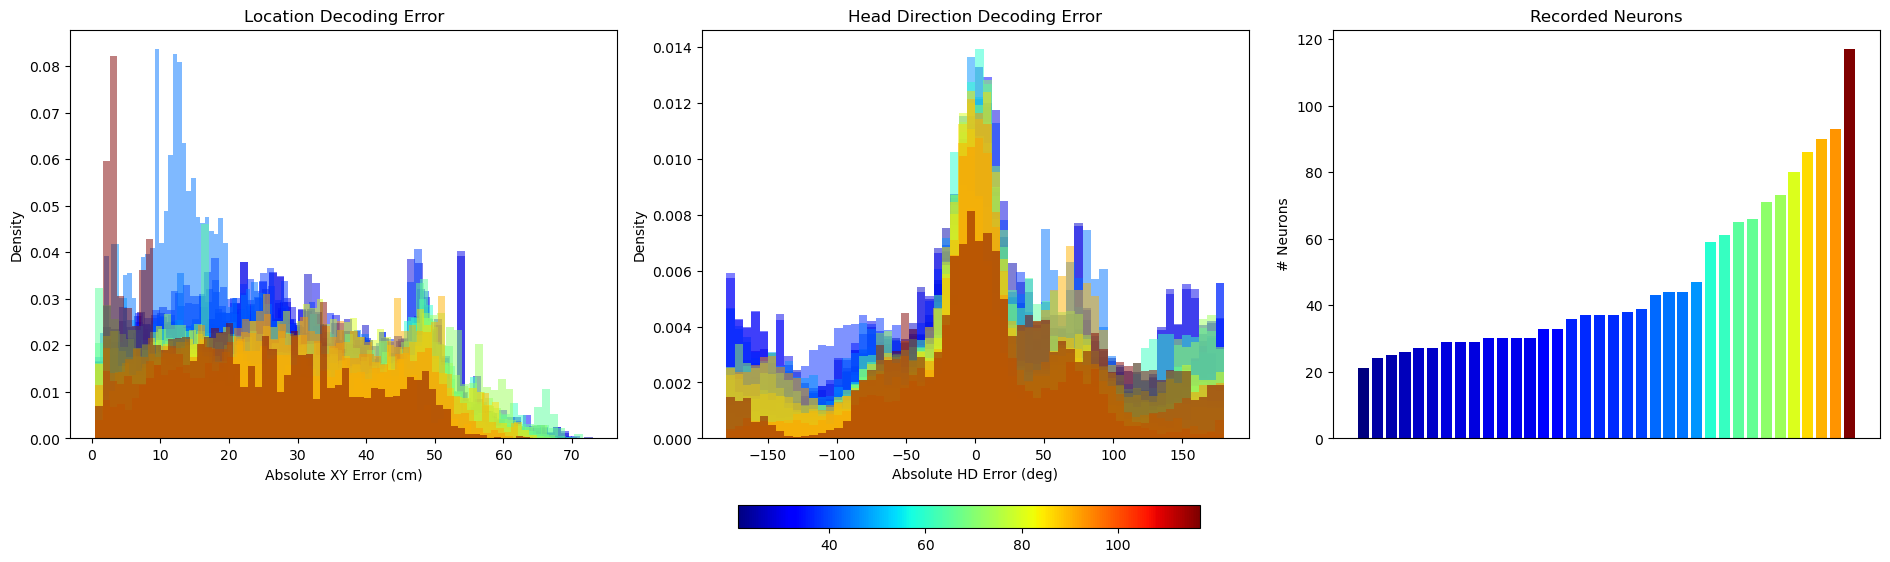

In [31]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import json

with open(save_path / 'hd_neuron_counts.json', 'r') as f:
    rat_neuron_dict = json.load(f)

pairs = sorted(rat_neuron_dict.items(), key=lambda x: x[1])
rats, rat_neurons = map(np.array, zip(*pairs))
rat_neurons = rat_neurons.astype(float)

precomp = []
for rat, n_neurons in zip(rats, rat_neurons):
    print(rat)
    rat_parts = rat.split('/')
    dataset = int(rat_parts[0][-1])
    session = rat_parts[1]
    if session in dusz_datasets[dataset] and dusz_datasets[dataset][session][0] != 'Square' and rat != 'Dataset_1/A3708-200317b': 
        print(f"Skipping {rat} due to non-square env")
        continue
    
    save_path_rat = save_path / f"{rat}"
    error_files_xy = sorted(save_path_rat.glob("errors_xy_cv*_10x10.npz"))
    error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_17.npz"))

    all_errors_xy, all_errors_hd = [], []
    skip_rat = False

    for f in error_files_xy:
        try:
            data = np.load(f, allow_pickle=True)
            d = data['stats'].item()
            if d.get('xy_median_abs_error', np.inf) < 1.0:  # dataset-specific filter
                print("skipping", rat)
                skip_rat = True
                break
            all_errors_xy.append(np.asarray(data["errors"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (XY): {e}")

    for f in error_files_hd:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_hd.append(np.asarray(data["errors_deg"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (HD): {e}")

    if skip_rat:
        print("skipping", rat)
        continue

    xy_arr = None
    if all_errors_xy:
        xy_arr = np.concatenate(all_errors_xy)
        xy_arr = xy_arr[xy_arr > 0.5]                # keep only >0.5
        xy_arr = xy_arr[~np.isnan(xy_arr)]
        if xy_arr.size == 0:
            print("skipping", rat)
            xy_arr = None

    hd_arr = None
    if all_errors_hd:
        hd_arr = np.concatenate(all_errors_hd)
        hd_arr = hd_arr[~np.isnan(hd_arr)]
        # keep absolute errors >= 0.5 deg (outside dead zone)
        hd_arr = hd_arr[(hd_arr <= -0.5) | (hd_arr >= 0.5)]
        if hd_arr.size == 0:
            print("skipping", rat)
            hd_arr = None

    # only keep rats that contribute something (or at least the bar)
    if ((xy_arr is not None) and (hd_arr is not None)) and np.isfinite(n_neurons):
        print("plotting!", rat)
        precomp.append({"rat": rat, "neurons": float(n_neurons), "xy": xy_arr, "hd": hd_arr})

if not precomp:
    raise RuntimeError("No rats left after filtering; nothing to plot.")

cmap = plt.get_cmap('jet')
neurons_filtered = np.array([d["neurons"] for d in precomp], dtype=float)
norm = Normalize(vmin=np.nanmin(neurons_filtered), vmax=np.nanmax(neurons_filtered))
colors = [cmap(norm(n)) for n in neurons_filtered]  # one color per surviving rat

# --- plotting ---
fig, axs = plt.subplots(1, 3, figsize=(19, 6))

# XY error histograms
for d, c in zip(precomp, colors):
    if d["xy"] is not None:
        axs[0].hist(d["xy"], bins=60, alpha=0.5, density=True, color=c)

axs[0].set_xlabel("Absolute XY Error (cm)")
axs[0].set_ylabel("Density")
axs[0].set_title("Location Decoding Error")

# HD error histograms
for d, c in zip(precomp, colors):
    if d["hd"] is not None:
        axs[1].hist(d["hd"], bins=60, alpha=0.5, density=True, color=c)

axs[1].set_xlabel("Absolute HD Error (deg)")
axs[1].set_ylabel("Density")
axs[1].set_title("Head Direction Decoding Error")

x = np.arange(len(precomp))
axs[2].bar(x, neurons_filtered, color=colors)
axs[2].set_xticks([]) 
axs[2].set_ylabel("# Neurons")
axs[2].set_title("Recorded Neurons")

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs, orientation='horizontal', fraction=0.05, pad=0.12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.26)  # leave space for colorbar
plt.savefig(current_file_path / 'figs/dusz_1d_decoding_hd_xy.png', dpi=300)
plt.show()

# just try seeing how many you can get only using the square environment, need at least 6 or 7
# rate map code doesn't work necessarily on circular environment
# also wanna see this for md and hd
# maybe just one plot with median absolute error for the main text bar graph for the selected sessions
# indicate on the EV scatter what is ADN and what's PoSub
# the schematic needs to have actual variance
# multiply two marginals together and GLM should fail

# A3708-200317b


### Decoding MD from Dusz HD cells

Dataset_5/A1113-180816
Skipping Dataset_5/A1113-180816 due to non-square env
Dataset_6/A1113-180816
Skipping Dataset_6/A1113-180816 due to non-square env
Dataset_6/A1801-181015
Skipping Dataset_6/A1801-181015 due to non-square env
Dataset_6/A1804-181225
Skipping Dataset_6/A1804-181225 due to non-square env
Dataset_5/A1112-180711
Skipping Dataset_5/A1112-180711 due to non-square env
Dataset_5/A1112-180709
Skipping Dataset_5/A1112-180709 due to non-square env
Dataset_5/A1113-180814
Skipping Dataset_5/A1113-180814 due to non-square env
Dataset_5/A1113-180813
Skipping Dataset_5/A1113-180813 due to non-square env
Dataset_5/A1106-180418
Skipping Dataset_5/A1106-180418 due to non-square env
Dataset_6/A1113-180813
Skipping Dataset_6/A1113-180813 due to non-square env
Dataset_5/A1110-180626
Skipping Dataset_5/A1110-180626 due to non-square env
Dataset_5/A1104-180328
Skipping Dataset_5/A1104-180328 due to non-square env
Dataset_5/A1106-180419
Skipping Dataset_5/A1106-180419 due to non-square env

/tmp/ipykernel_1008717/3692549464.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


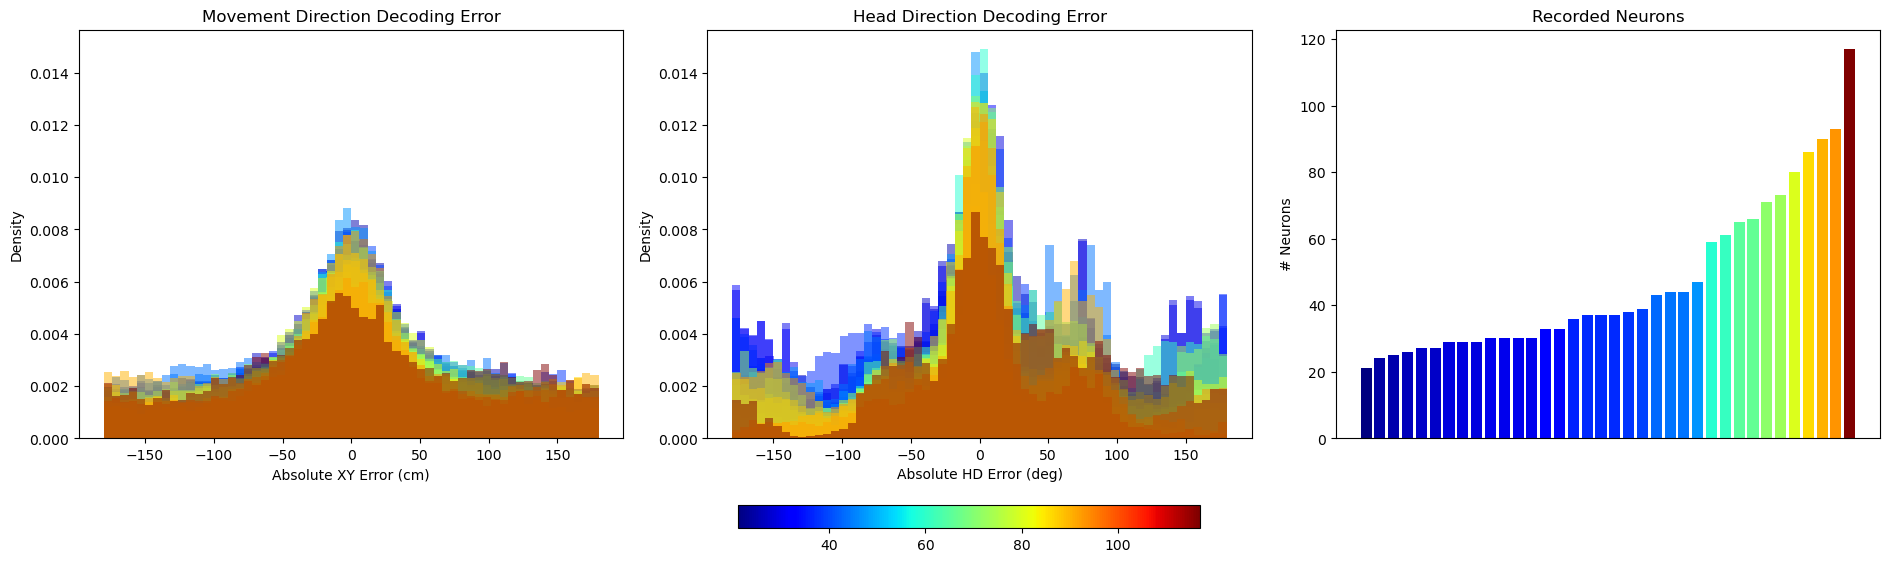

In [32]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import json

with open(save_path / 'hd_neuron_counts.json', 'r') as f:
    rat_neuron_dict = json.load(f)

pairs = sorted(rat_neuron_dict.items(), key=lambda x: x[1])
rats, rat_neurons = map(np.array, zip(*pairs))
rat_neurons = rat_neurons.astype(float)

precomp = []
for rat, n_neurons in zip(rats, rat_neurons):
    print(rat)
    rat_parts = rat.split('/')
    dataset = int(rat_parts[0][-1])
    session = rat_parts[1]
    if session in dusz_datasets[dataset] and dusz_datasets[dataset][session][0] != 'Square' and rat != 'Dataset_1/A3708-200317b': # envType
        print(f"Skipping {rat} due to non-square env")
        continue
    
    save_path_rat = save_path / f"{rat}"
    error_files_xy = sorted(save_path_rat.glob("errors_md_cv*_17.npz"))
    error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_17.npz"))

    all_errors_xy, all_errors_hd = [], []

    for f in error_files_xy:
        try:
            data = np.load(f, allow_pickle=True)
            d = data['stats'].item()
            all_errors_xy.append(np.asarray(data["errors_deg"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (XY): {e}")

    for f in error_files_hd:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_hd.append(np.asarray(data["errors_deg"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (HD): {e}")

    if rat == 'Dataset_4/A8603-210602':
        print('skipping')
        continue

    xy_arr = None
    if all_errors_xy:
        xy_arr = np.concatenate(all_errors_xy)
        #xy_arr = xy_arr[(xy_arr <= -0.5) | (xy_arr >= 0.5)]
        xy_arr = xy_arr[~np.isnan(xy_arr)]
        if xy_arr.size == 0:
            print("all nans md")
            xy_arr = None

    hd_arr = None
    if all_errors_hd:
        hd_arr = np.concatenate(all_errors_hd)
        hd_arr = hd_arr[~np.isnan(hd_arr)]
        #hd_arr = hd_arr[(hd_arr <= -0.5) | (hd_arr >= 0.5)]
        if hd_arr.size == 0:
            print("all nans hd")
            hd_arr = None
    
    # only keep rats that contribute something (or at least the bar)
    if ((xy_arr is not None) and (hd_arr is not None)) and np.isfinite(n_neurons):
        print('plottin', rat)
        precomp.append({"rat": rat, "neurons": float(n_neurons), "xy": xy_arr, "hd": hd_arr})

if not precomp:
    raise RuntimeError("No rats left after filtering; nothing to plot.")

cmap = plt.get_cmap('jet')
neurons_filtered = np.array([d["neurons"] for d in precomp], dtype=float)
norm = Normalize(vmin=np.nanmin(neurons_filtered), vmax=np.nanmax(neurons_filtered))
colors = [cmap(norm(n)) for n in neurons_filtered]  # one color per surviving rat

# --- plotting ---
fig, axs = plt.subplots(1, 3, figsize=(19, 6))

# XY error histograms
for d, c in zip(precomp, colors):
    if d["xy"] is not None:
        axs[0].hist(d["xy"], bins=60, alpha=0.5, density=True, color=c)

axs[0].set_xlabel("Absolute XY Error (cm)")
axs[0].set_ylabel("Density")
axs[0].set_title("Movement Direction Decoding Error")

# HD error histograms
for d, c in zip(precomp, colors):
    if d["hd"] is not None:
        axs[1].hist(d["hd"], bins=60, alpha=0.5, density=True, color=c)

axs[1].set_xlabel("Absolute HD Error (deg)")
axs[1].set_ylabel("Density")
axs[1].set_title("Head Direction Decoding Error")

x = np.arange(len(precomp))
axs[2].bar(x, neurons_filtered, color=colors)
axs[2].set_xticks([]) 
axs[2].set_ylabel("# Neurons")
axs[2].set_title("Recorded Neurons")

axs[0].set_ylim(axs[1].get_ylim())

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs, orientation='horizontal', fraction=0.05, pad=0.12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.26)  # leave space for colorbar
plt.savefig(current_file_path / 'figs/dusz_1d_decoding_hd_md.png', dpi=300)
plt.show()

# just try seeing how many you can get only using the square environment, need at least 6 or 7
# rate map code doesn't work necessarily on circular environment
# also wanna see this for md and hd
# maybe just one plot with median absolute error for the main text bar graph for the selected sessions
# indicate on the EV scatter what is ADN and what's PoSub
# the schematic needs to have actual variance
# multiply two marginals together and GLM should fail

# I'm skipping dataset 4 here because it's normalized or something differently than everything else, it's not even different units it's just different



In [23]:
# %% [markdown]
# Collect a dictionary of session titles -> HD neuron counts for Dusz dataset

# %% 
from pathlib import Path
import numpy as np
from scipy.io import loadmat

# -- robust MATLAB struct extractor (matches your pipeline) --
def _extract_matlab_obj(obj):
    try:
        from scipy.io.matlab._mio5_params import mat_struct
    except Exception:
        mat_struct = ()  # fallback if internal path changes
    if not (isinstance(obj, dict) or isinstance(obj, mat_struct)):
        return obj
    d = obj.__dict__ if hasattr(obj, "__dict__") else obj
    out = {}
    for k, v in d.items():
        if k in ["_fieldnames", "type", "time_unit", "data_unit", "name"]:
            continue
        if hasattr(v, "__dict__") or isinstance(v, dict):
            out[k] = _extract_matlab_obj(v)
        elif isinstance(v, np.ndarray):
            out[k] = np.array([_extract_matlab_obj(x) for x in v])
        else:
            out[k] = v
    return out

def _to_1d_int(arr):
    a = np.asarray(arr).ravel()
    # convert booleans or truthy to ints
    if a.dtype == bool:
        a = a.astype(int)
    return a.astype(int, copy=False)

def count_hd_neurons(celltypes_mat_path: Path) -> int:
    """Return number of HD neurons (hd == 1) from a Dusz CellTypes.mat file."""
    ct_raw = loadmat(celltypes_mat_path, struct_as_record=False, squeeze_me=True)
    # Commonly the struct is under 'CellTypes', but support variants.
    ct = _extract_matlab_obj(ct_raw.get('CellTypes', ct_raw))
    # Try several likely places for the hd vector
    candidates = [
        ct.get('hd'),
        ct_raw.get('hd'),
        (ct.get('labels', {}) if isinstance(ct.get('labels'), dict) else {}).get('hd'),
    ]
    hd_vec = None
    for c in candidates:
        if c is not None and np.size(c) > 0:
            hd_vec = _to_1d_int(c)
            break
    if hd_vec is None:
        raise FileNotFoundError(f"Couldn't find 'hd' labels in {celltypes_mat_path}")
    # Convention: hd == 1 means HD cell
    return int(np.sum(hd_vec == 1))

def gather_hd_counts(
    data_root: Path = Path("./data/dusz"),
    sessions: list[tuple[int, str]] | None = None,
) -> dict[str, int]:
    """
    Build { 'Dataset_{id}/RAT': hd_count }.
    If `sessions` is None, auto-discovers all Dataset_*/*/Data/CellTypes.mat.
    """
    results: dict[str, int] = {}
    if sessions is None:
        for ct_path in sorted(data_root.glob("Dataset_*/*/Data/CellTypes.mat")):
            dataset_str = ct_path.parts[-4]  # "Dataset_{id}"
            rat = ct_path.parts[-3]
            title = f"{dataset_str}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception as e:
                results[title] = -1  # mark failure
    else:
        for ds_id, rat in sessions:
            ct_path = data_root / f"Dataset_{ds_id}" / rat / "Data" / "CellTypes.mat"
            title = f"Dataset_{ds_id}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception:
                results[title] = -1
    return results


hd_counts = gather_hd_counts(Path("/home/mag/variance-analysis/data/dusz"), sessions=session_list)

# Print the dictionary (and a neat summary)
print(hd_counts)
print("\nSummary:")
ok = {k: v for k, v in hd_counts.items() if v >= 0}
fail = [k for k, v in hd_counts.items() if v < 0]
print(f"  Sessions found: {len(hd_counts)}")
print(f"  With counts    : {len(ok)} (total HD neurons = {sum(ok.values())})")
if fail:
    print(f"  Failed to read : {len(fail)} -> {fail}")


import json
from pathlib import Path

# --- after computing hd_counts ---
output_path = Path("/home/mag/variance-analysis/data/dusz/hd_neuron_counts.json")

# Save dictionary to JSON
with open(output_path, "w") as f:
    json.dump(hd_counts, f, indent=2)  # indent makes it nicely formatted

print(f"Saved HD counts to {output_path}")

# --- later on, when you want to load it ---
with open(output_path, "r") as f:
    loaded_hd_counts = json.load(f)

print("Loaded HD counts:", loaded_hd_counts)



{'Dataset_1/A3701-191119': 71, 'Dataset_1/A3702-191126': 61, 'Dataset_1/A3703-191215': 65, 'Dataset_1/A3705-200306': 66, 'Dataset_1/A3706-200313': 86, 'Dataset_1/A3707-200317': 117, 'Dataset_1/A3708-200317b': 44, 'Dataset_1/A3709-200601': 21, 'Dataset_1/A3710-200609': 80, 'Dataset_1/A3711-200810b': 90, 'Dataset_1/A3712-200903a': 73, 'Dataset_1/A3713-200909a': 25, 'Dataset_1/A3716-201015b': 93, 'Dataset_1/A3717-201021': 59, 'Dataset_1/A3723-201115': 37, 'Dataset_1/A3728-210309b': 27, 'Dataset_1/A3730-210323b': 47, 'Dataset_2/A1808-190807': 29, 'Dataset_2/A1813-190408': 30, 'Dataset_2/A1815-190523': 33, 'Dataset_2/A1821-190910': 37, 'Dataset_2/A1824-190827': 39, 'Dataset_2/A5505-200831': 30, 'Dataset_2/A5506-200914a': 24, 'Dataset_2/A5507-200920': 43, 'Dataset_2/A5508-200930': 33, 'Dataset_2/A5801-200924': 26, 'Dataset_2/A6211-210407': 36, 'Dataset_2/A6215-210610': 29, 'Dataset_2/A6216-210623': 44, 'Dataset_2/A9701-210805': 38, 'Dataset_3/A3702-191128': 63, 'Dataset_3/A3706-200315': 67, 